# Seaborn — Statistical Plotting in Python

**Definition.** Seaborn is a visualization library **built on top of Matplotlib**. Where Matplotlib
draws *shapes you specify*, Seaborn draws *statistical relationships you name* — it reads columns
from a `DataFrame`, does the grouping and aggregation itself, and picks sensible colours and layout.

The practical difference, on the same grouped bar chart:

```python
# Matplotlib - you compute the means, the offsets and the colours yourself
x = np.arange(len(days)); width = 0.4
plt.bar(x - width/2, male_means, width); plt.bar(x + width/2, female_means, width)
plt.xticks(x, days); plt.legend()

# Seaborn - you name the columns; it groups, averages and colours for you
sns.barplot(data=tips_df, x='day', y='total_bill', hue='sex')
```

Seaborn returns Matplotlib objects, so **everything from the Matplotlib notebook still applies** —
titles, limits, `savefig`, subplots. Seaborn is a layer on top, not a replacement.

### Tidy ("long-form") data

Seaborn expects **one row per observation, one column per variable**:

| total_bill | tip | sex | smoker | day | time | size |
| --- | --- | --- | --- | --- | --- | --- |
| 16.99 | 1.01 | Female | No | Sun | Dinner | 2 |
| 10.34 | 1.66 | Male | No | Sun | Dinner | 3 |

Given that shape, a plot is just a mapping from **column names** to **visual properties**:

| Argument | Maps a column to… |
| --- | --- |
| `x`, `y` | position |
| `hue` | colour |
| `size` | marker size / line width |
| `style` | marker shape / line dash pattern |
| `col`, `row` | **separate panels** (figure-level functions only) |

These are called **semantic mappings**, and each one automatically gets a legend entry.

### The one distinction that matters: figure-level vs axes-level

| | **Axes-level** | **Figure-level** |
| --- | --- | --- |
| Examples | `scatterplot` `lineplot` `barplot` `boxplot` `histplot` `heatmap` | `relplot` `displot` `catplot` `lmplot` |
| Draws onto | a single Matplotlib **Axes** | its own **whole figure** |
| Returns | `matplotlib.axes.Axes` | a seaborn `FacetGrid` |
| Accepts `ax=` | **yes** | **no** |
| Can facet with `col=` / `row=` | no | **yes** |
| Combine with `plt.subplots()` | yes | no |

**Rule of thumb:** use a **figure-level** function to explore quickly and to split into panels with
`col=`; use an **axes-level** function whenever the chart is going into a layout you control — which
is the recommended pattern shown in section 6.

Every figure-level function is a wrapper that dispatches to axes-level ones via `kind=`:

| Figure-level | `kind=` options |
| --- | --- |
| `relplot` | `'scatter'` (default), `'line'` |
| `displot` | `'hist'` (default), `'kde'`, `'ecdf'` |
| `catplot` | `'strip'` (default), `'box'`, `'violin'`, `'bar'`, `'count'`, `'point'` |

### Contents

| § | Topic | Functions |
| --- | --- | --- |
| **1** | Setup and datasets | `set_theme`, `get_dataset_names`, `load_dataset` |
| **2** | Relational plots | `relplot`, `scatterplot`, `lineplot` |
| **3** | Categorical plots | `barplot`, `boxplot` |
| **4** | Distribution plots | `histplot` |
| **5** | Matrix plots | `pivot` + `heatmap` |
| **6** | Best practice | Seaborn inside the Matplotlib OO API (`ax=`) |
|  | Summary | cheat sheet and gotchas |

**Versions used here:** seaborn 0.13.2, pandas 2.3.3, matplotlib 3.10.


---
## 1. Setup and the built-in datasets

**Definition.** Seaborn is imported as `sns` by convention, alongside `matplotlib.pyplot` — the two
are used together, since Seaborn draws the statistics and Matplotlib handles titles, layout and
saving.

**Usage**

```python
import seaborn as sns
import matplotlib.pyplot as plt
```

**Actions in the cell below**
- `import seaborn as sns` — the universal alias.
- `import matplotlib.pyplot as plt` — **not optional in practice**: Seaborn has no `show()`,
  `savefig()` or `subplots()` of its own, so anything beyond the plot itself goes through `plt`.

Install with `pip install seaborn` (it pulls in matplotlib, pandas and numpy as dependencies).


In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

### 1.1 `sns.set_theme()` and the dataset catalogue

**Definition.** `set_theme()` applies Seaborn's default styling — grid, background, colour palette
and font scaling — to **all** subsequent plots, Matplotlib's included. `get_dataset_names()` lists
the example datasets hosted in the `seaborn-data` repository.

**Usage**

```python
sns.set_theme()                      # apply defaults
sns.set_theme(style='whitegrid')     # pick a style
sns.get_dataset_names()              # list available example datasets
```

| `style=` | Look |
| --- | --- |
| `'darkgrid'` | grey background with white grid — the default |
| `'whitegrid'` | white background, grey grid |
| `'dark'` / `'white'` | no grid |
| `'ticks'` | white with axis ticks — the style used in the next cell |

Other useful arguments: `context=` (`'paper'`, `'notebook'`, `'talk'`, `'poster'`) scales all fonts
and line widths at once, and `palette=` sets the default colour cycle.

**Actions in the cell below**
- `sns.set_theme()` — switch on Seaborn's defaults. This is a **global** setting, exactly like
  `plt.style.use()`, and it restyles Matplotlib charts too. Importing seaborn alone does *not* do
  this; `set_theme()` is the opt-in.
- `sns.get_dataset_names()` — returns the list of example datasets. **This one needs an internet
  connection** — it queries GitHub, so it raises a network error offline.

These datasets exist so examples are reproducible; for your own work you'd pass any `DataFrame`.


In [2]:
sns.set_theme()
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

### 1.2 Loading a dataset — `tips`

**Definition.** `sns.load_dataset(name)` downloads one of the example datasets and returns it as a
pandas `DataFrame` (cached after the first fetch).

**Usage**

```python
tips_df = sns.load_dataset('tips')
tips_df.head()
```

**Actions in the cell below**
- `sns.load_dataset('tips')` — **244 rows** of restaurant bills, one row per table served.
- `.head()` — the first five rows, so the column names and types are visible before plotting. Worth
  doing every time: in Seaborn you plot **by column name**, so knowing the columns *is* knowing the
  API.

**The `tips` columns**

| Column | Type | Meaning |
| --- | --- | --- |
| `total_bill` | numeric | bill in dollars |
| `tip` | numeric | tip in dollars |
| `sex` | category | Male / Female |
| `smoker` | category | Yes / No |
| `day` | category | Thur / Fri / Sat / Sun |
| `time` | category | Lunch / Dinner |
| `size` | numeric | number of diners at the table |

Two numeric columns plus four categoricals is why `tips` appears in nearly every Seaborn tutorial —
`x`, `y`, `hue`, `size` and `style` can all be filled from one table.


In [3]:
tips_df = sns.load_dataset('tips')
tips_df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


---
## 2. Relational Plots

**Definition.** Relational plots show **how two numeric variables relate**. Seaborn splits this into
one figure-level entry point and two axes-level workers:

| Function | Level | Draws |
| --- | --- | --- |
| `sns.relplot(kind='scatter'/'line')` | figure | dispatches to one of the two below, and can facet |
| `sns.scatterplot()` | axes | one point per observation |
| `sns.lineplot()` | axes | a line, **aggregating repeated x values** |

**Usage**

```python
sns.relplot(data=df, x='a', y='b', hue='c', col='d')   # figure-level, can facet
sns.scatterplot(data=df, x='a', y='b', hue='c')        # axes-level
sns.lineplot(data=df, x='a', y='b')                    # axes-level
```

**Scatter vs line** is the same choice as in Matplotlib: scatter for *do these two move together*,
line for *how does this change along an ordered axis*.


### 2.1 `relplot` — the figure-level entry point

**Definition.** `sns.relplot()` creates its **own figure** and returns a `FacetGrid`. Three semantic
mappings are used at once here, so a single call encodes **five variables**: two on position, and
three more through colour, size and shape.

**Usage**

```python
sns.set_theme(style='ticks')
sns.relplot(data=tips_df, x='total_bill', y='tip',
            hue='smoker', size='size', style='smoker')
```

**Actions in the cell below**
- `sns.set_theme(style="ticks")` — switch to the clean ticked style; global, as in 1.1.
- `data=tips_df` — the DataFrame. Everything after this refers to **column names**, not arrays.
- `x='total_bill'`, `y='tip'` — position.
- `hue='smoker'` — colour by smoker/non-smoker; a legend is generated automatically.
- `size='size'` — marker area scales with the number of diners.
- `style='smoker'` — marker **shape** also splits on smoker. Deliberately doubled with `hue`:
  redundant encoding, which keeps the groups distinguishable in greyscale or for colour-blind
  readers.
- `kind` is omitted, so it defaults to `'scatter'`.
- The cell echoes `<seaborn.axisgrid.FacetGrid at 0x…>` — the **giveaway that this is figure-level**.
  An axes-level function would echo an `Axes` instead.

**What it shows:** tips rise with the bill (the expected diagonal), with wide scatter at higher
bills, and no obvious separation between smokers and non-smokers.

**Because it's figure-level, it can facet.** Add `col=` to split into panels:

```python
sns.relplot(data=tips_df, x='total_bill', y='tip', hue='smoker', col='time')
```

That is what `relplot` buys you over `scatterplot` — and the reason it refuses an `ax=` argument.


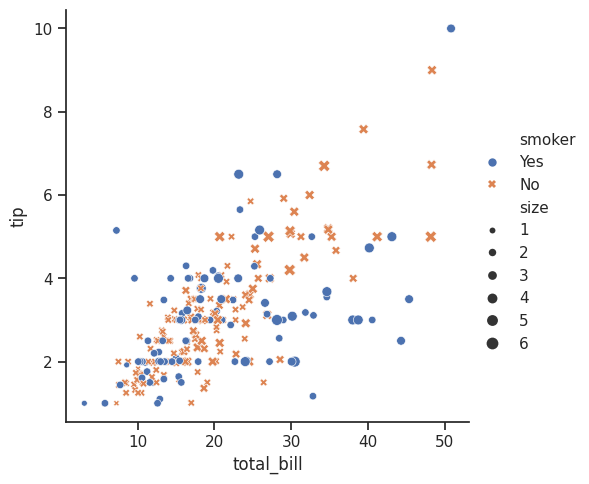

In [4]:
sns.set_theme(style="ticks")
sns.relplot(data=tips_df, x='total_bill', y='tip',hue='smoker',size='size',style='smoker')

### 2.2 `relplot` without a DataFrame — plain vectors and `kind='line'`

**Definition.** `data=` is optional. Passing lists or arrays directly to `x` and `y` makes Seaborn
behave like a thin wrapper over Matplotlib — useful for quick throwaway plots where there's no
DataFrame to speak of.

**Usage**

```python
sns.relplot(x=x_val, y=y_val, kind='line')
```

**Actions in the cell below**
- `x_val` / `y_val` — plain Python lists, `y = x²` via a list comprehension. No `data=` argument.
- `kind='line'` — switches `relplot` from its default `'scatter'` to dispatch to `lineplot`
  instead. This is how every figure-level function selects its drawing routine.
- The result is still a `FacetGrid` — figure-level behaviour doesn't depend on whether the input was
  a DataFrame.

**The trade-off.** Without column names Seaborn has nothing to label the axes with, so they come out
as a bare `x` and `y`, and `hue`/`col` have nothing to group by. Seaborn's value *is* the DataFrame
integration — with loose vectors, `plt.plot()` is the simpler tool.


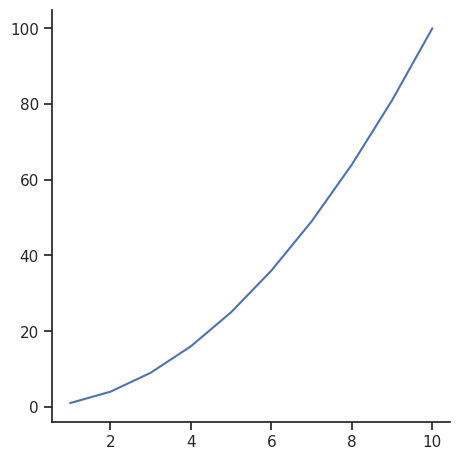

In [5]:
x_val = [1,2,3,4,5,6,7,8,9,10]
y_val = [i**2 for i in x_val]
sns.relplot(x = x_val, y = y_val, kind='line')

### 2.3 `scatterplot` — the axes-level equivalent

**Definition.** `sns.scatterplot()` draws the same marks as `relplot(kind='scatter')` but onto the
**current Axes**, and returns that `Axes`. No new figure, no faceting — which is exactly what makes
it composable with Matplotlib.

**Usage**

```python
sns.scatterplot(data=tips_df, x='total_bill', y='tip', hue='time', size='size')
```

**Actions in the cell below**
- Same `x`/`y` as 2.1, but `hue='time'` — colour by Lunch vs Dinner instead of smoker.
- `size='size'` — marker area by party size again.
- No `style=`, so all markers are circles.
- The cell echoes `<Axes: xlabel='total_bill', ylabel='tip'>` — an **Axes**, not a FacetGrid.
  Compare with 2.1: that return type is the whole distinction between the two levels.

**Why this one is usually the better default.** Because it returns an Axes and accepts `ax=`, it
slots into `plt.subplots()` grids, and every Matplotlib method — `ax.set_title()`, `ax.set_ylim()`,
`fig.savefig()` — works on the result. Section 6 shows that pattern.

**Note on `size=`:** Seaborn scales the marker area between sensible bounds automatically. Control
the range with `sizes=(20, 200)` if the default contrast is too weak.


<Axes: xlabel='total_bill', ylabel='tip'>

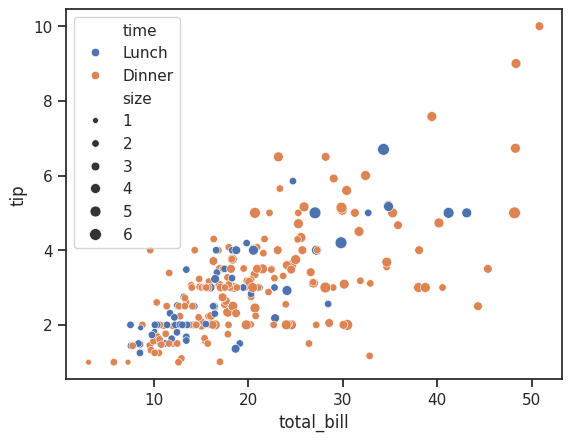

In [6]:
#Relational plots
#1.scatter plots
sns.scatterplot(data=tips_df, x='total_bill', y='tip',hue='time',size='size')

### 2.4 A second dataset — `flights`

**Definition.** The `flights` dataset is the standard example of **time-series-shaped tidy data**:
monthly airline passenger totals from 1949 to 1960.

**Usage**

```python
flights_df = sns.load_dataset('flights')
flights_df.head()
```

**Actions in the cell below**
- Loads **144 rows** — 12 years × 12 months, one row per month.
- `.head()` shows the three columns:

| Column | Meaning |
| --- | --- |
| `year` | 1949 – 1960 |
| `month` | Jan – Dec (a category) |
| `passengers` | thousands of passengers that month |

**The important structural fact:** there are **12 rows per year**, one per month. So plotting
`x='year'` gives Seaborn *twelve* y-values at each x — and that repetition is precisely what the
next cell's confidence band is built from.


In [7]:
#2.line plots
flights_df = sns.load_dataset('flights')
flights_df.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


### 2.5 `lineplot` — automatic aggregation and confidence intervals

**Definition.** When a `lineplot` finds **multiple y values at the same x**, it does not draw a
zig-zag through all of them. It **aggregates**: the line is the *mean* at each x, and the shaded band
around it is a **95% confidence interval** for that mean, bootstrapped from the data.

**Usage**

```python
sns.lineplot(data=flights_df, x='year', y='passengers')                      # mean + 95% CI
sns.lineplot(data=flights_df, x='year', y='passengers', errorbar=None)       # line only
sns.lineplot(data=flights_df, x='year', y='passengers', errorbar=('ci', 99)) # 99% CI
sns.lineplot(data=flights_df, x='year', y='passengers', estimator='median')  # median instead
```

| Argument | Default | Meaning |
| --- | --- | --- |
| `estimator` | `'mean'` | how repeated y values are collapsed |
| `errorbar` | `('ci', 95)` | the shaded band; `None` removes it, `'sd'` uses standard deviation |

**Actions in the cell below**
- `sns.lineplot(data=flights_df, x='year', y='passengers')` — **one line for twelve years**, even
  though there are 144 rows. Seaborn groups by `year`, averages the 12 monthly values, and plots the
  means.
- The comment in the cell records exactly this: the shading is the **mean and its 95% confidence
  interval**, on by default.

**What it shows:** passenger numbers climb steadily year on year, and the band **widens** over time —
later years have far more month-to-month variation (summer peaks pulling away from winter troughs),
so the mean is less precisely pinned.

**The gotcha worth internalising.** A `lineplot` that silently averages is convenient but easy to
misread as raw data. If you want every month drawn rather than collapsed, give Seaborn the extra
variable to split on:

```python
sns.lineplot(data=flights_df, x='year', y='passengers', hue='month')   # 12 separate lines
```


<Axes: xlabel='year', ylabel='passengers'>

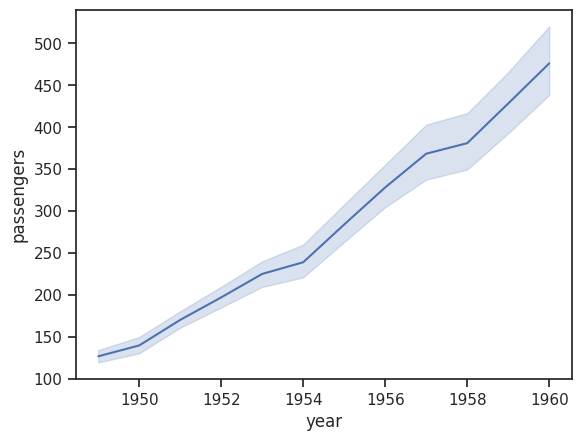

In [8]:
sns.lineplot(data=flights_df, x='year', y='passengers')
#shading : mean and confidence interval default is 95% confidence interval

---
## 3. Categorical Plots

**Definition.** Categorical plots put a **category on one axis and a numeric value on the other**.
Seaborn's family covers `barplot`, `boxplot`, `violinplot`, `stripplot`, `swarmplot`, `pointplot`
and `countplot`, all reachable from the figure-level `sns.catplot(kind=...)`.

**Usage**

```python
sns.barplot(data=df, x='cat', y='num', hue='group')       # axes-level
sns.catplot(data=df, x='cat', y='num', kind='box')        # figure-level, can facet
```

| Function | Shows |
| --- | --- |
| `barplot` | an **estimate** per category (mean by default) with an error bar |
| `countplot` | how many **rows** per category (no `y` needed) |
| `boxplot` | the five-number summary per category |
| `violinplot` | the full distribution shape per category |
| `stripplot` / `swarmplot` | every individual observation |

**`barplot` vs `countplot`** trips people up: `barplot` averages a numeric column, `countplot` counts
rows.


### 3.1 `barplot` — grouped bars in one line

**Definition.** `sns.barplot()` groups the rows by category, applies an **estimator** (the mean, by
default) to the `y` column, and draws one bar per group with an error bar showing the 95% confidence
interval of that estimate.

**Usage**

```python
sns.barplot(data=tips_df, x='day', y='total_bill', hue='sex')
sns.barplot(data=tips_df, x='day', y='total_bill', estimator='median', errorbar=None)
```

**Actions in the cell below**
- `x='day'` — one group per day of the week.
- `y='total_bill'` — the numeric column being averaged. Each bar is the **mean bill**, *not* a sum
  and *not* a row count.
- `hue='sex'` — splits each day into two adjacent bars, with the legend generated automatically.
- The vertical line on each bar is the **95% confidence interval** — turn it off with
  `errorbar=None`.

**The comment in the cell is the point:** *"in matplotlib this is somewhat complex."* Compare with
section 3.4 of the Matplotlib notebook, where the same grouped bars required computing the group
means yourself, then `np.arange` slot positions, then `± width/2` offsets, then `plt.xticks()` to
restore the labels. Here `hue='sex'` does all of it — **and** adds the error bars, which the manual
version never had.

**Two things to know**
1. **Bar order follows the data**, so `tips` comes out Thur, Fri, Sat, Sun by category order rather
   than sorted by value. Control it explicitly with `order=['Thur', 'Fri', 'Sat', 'Sun']`.
2. **Bars start at zero** by default — correct, and the same rule flagged in the Matplotlib
   notebook. Don't override it with `ax.set_ylim()` to "zoom in".


<Axes: xlabel='day', ylabel='total_bill'>

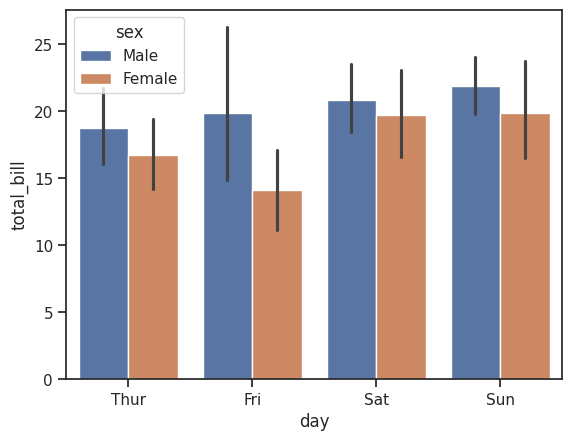

In [9]:
#Categorical plots
sns.barplot(data=tips_df, x='day', y='total_bill',hue='sex') # in matplot lib this is some waht complex

### 3.2 `boxplot` — distributions per category

**Definition.** `sns.boxplot()` draws the five-number summary (min, Q1, median, Q3, max, plus
outliers past `1.5 × IQR`) for each category — the same construction as `plt.boxplot()`, but grouped
straight from a DataFrame.

**Usage**

```python
sns.boxplot(data=tips_df, x='day', y='tip', hue='sex')
```

**Actions in the cell below**
- `x='day'`, `y='tip'` — one box per day, summarising that day's tips.
- `hue='sex'` — two boxes side by side within each day, so **eight** distributions are compared on
  one shared scale.
- Outliers appear automatically as separate diamonds; no `flierprops` needed.

**Why this is where Seaborn pulls ahead.** In Matplotlib, `plt.boxplot()` takes a *list of lists* —
you have to split the DataFrame into eight groups yourself and keep the labels aligned. Here the
grouping is declarative: name the two columns and you're done.

**`barplot` vs `boxplot` on the same data:** the bar shows one number (the mean) with a
confidence interval; the box shows the **whole spread** — median, quartiles and outliers. When
distributions are skewed or have outliers, the box tells the more honest story, which is why box
plots are preferred for exploration and bars for reporting a single headline figure.

**Related:** `sns.violinplot()` swaps the box for a mirrored density curve, showing the actual shape
— including a two-peaked distribution, which a box plot cannot reveal.


<Axes: xlabel='day', ylabel='tip'>

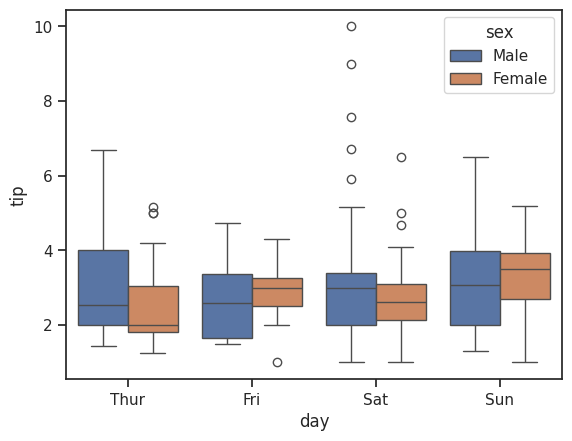

In [10]:
#box plot
sns.boxplot(data=tips_df, x='day', y='tip',hue='sex')

---
## 4. Distribution Plots

**Definition.** Distribution plots show how a **single variable is spread out**. The family is
`histplot` (counts in bins), `kdeplot` (a smoothed density curve), `ecdfplot` (cumulative), and
`rugplot` (ticks for individual observations) — all reachable from the figure-level
`sns.displot(kind=...)`.

**Usage**

```python
sns.histplot(data=df, x='col')                      # counts per bin
sns.histplot(data=df, x='col', kde=True)            # histogram + density curve
sns.histplot(data=df, x='col', hue='group')         # one distribution per group
sns.displot(data=df, x='col', col='group')          # figure-level, one panel per group
```

| Argument | Meaning |
| --- | --- |
| `bins` | bin count or explicit edges — default `'auto'` |
| `kde` | `True` overlays a smoothed density estimate |
| `hue` | separate, overlaid distributions per group |
| `multiple` | `'layer'` (default), `'stack'`, `'dodge'`, `'fill'` — how `hue` groups are arranged |
| `stat` | `'count'` (default), `'density'`, `'probability'`, `'percent'` |

**Actions in the cell below**
- `penguins_df = sns.load_dataset('penguins')` — **344 rows**, one per measured penguin, with
  species, island, bill and flipper measurements, body mass and sex.
- `penguins_df.head()` — inspect the columns. Its table appears as a separate output above the
  chart, because the cell displays it before the plotting call runs.
- `sns.histplot(data=penguins_df, x='body_mass_g')` — the distribution of body mass. Only `x` is
  given; the y-axis is the **count** Seaborn computes.
- `bins` is not specified, so Seaborn chooses automatically — a better default than Matplotlib's
  fixed 10, though still worth overriding to check the shape is stable.

**What it shows:** the distribution is **right-skewed with a hint of two peaks** — lighter penguins
around 3500 g and a second cluster near 5000 g. That is the signature of mixed groups, and adding
`hue='species'` reveals it directly: Gentoo penguins are substantially heavier than Adelie and
Chinstrap.

**Missing data:** `body_mass_g` has 2 nulls. Seaborn drops them silently — convenient, but it means
the plotted count can be lower than `len(df)` without warning.


<Axes: xlabel='body_mass_g', ylabel='Count'>

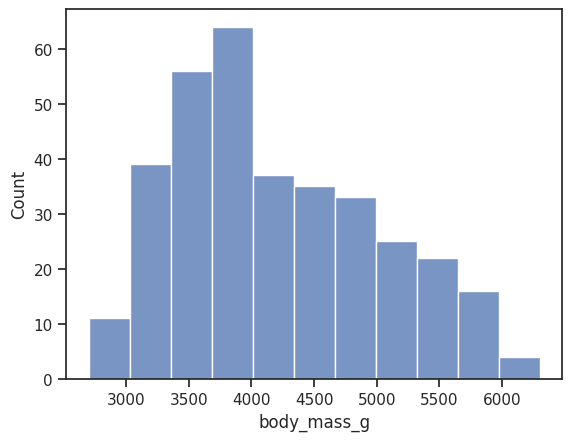

In [11]:
#Distribution plots
penguins_df = sns.load_dataset('penguins')
penguins_df.head()
sns.histplot(data=penguins_df, x='body_mass_g')

---
## 5. Matrix Plots — `heatmap`

**Definition.** A heatmap encodes the values of a **2-D matrix as colours**, one coloured cell per
value. It is the tool for showing a numeric quantity across **two categorical axes at once** —
month × year, product × region, or a correlation matrix.

**The one requirement that makes it different:** every other function in this notebook takes *tidy*
long-form data. `sns.heatmap()` takes **wide-form data** — a DataFrame already shaped like the grid
you want drawn, with the row index as one axis and the columns as the other. Reshaping long → wide is
what `DataFrame.pivot()` is for.

**Usage**

```python
wide = long.pivot(index='month', columns='year', values='passengers')
sns.heatmap(wide, annot=True, fmt='d', cmap='YlGnBu')
```

| Argument | Meaning |
| --- | --- |
| `annot` | `True` writes the value inside each cell |
| `fmt` | format for those annotations — `'d'` integer, `'.1f'` one decimal, `'.0%'` percent |
| `cmap` | colormap — sequential (`'YlGnBu'`, `'viridis'`) for magnitudes, diverging (`'coolwarm'`) around a midpoint |
| `linewidths` | gap between cells |
| `vmin` / `vmax` / `center` | pin the colour scale, e.g. `center=0` for a correlation matrix |
| `cbar` | `False` hides the colour bar |


### 5.1 Re-inspecting `flights` before reshaping

**Definition.** A look at the long-form data immediately before pivoting it — worth doing, because
the pivot's three arguments map directly onto three of these columns.

**Actions in the cell below**
- `flights_df.head()` — the same 144-row long-form table from 2.4: one row per month, three columns.
- The `#Relational plots` comment is **left over from section 2** and doesn't describe this cell;
  this is the matrix-plot section. Harmless, but worth correcting to `#Matrix plots`.

**Long vs wide, which is the whole point of the next cell**

```
LONG (tidy) - what every other seaborn function wants
  year  month  passengers
  1949  Jan    112
  1949  Feb    118

WIDE (matrix) - what heatmap wants
  month | 1949  1950  1951 ...
  Jan   |  112   115   145
  Feb   |  118   126   150
```

Both hold identical numbers; only the shape differs.


In [12]:
#Relational plots
flights_df.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


### 5.2 `pivot` + `heatmap` — 144 numbers in one picture

**Definition.** `DataFrame.pivot()` reshapes long-form data into a matrix by naming which column
becomes the rows, which becomes the columns, and which fills the cells. `sns.heatmap()` then colours
that matrix.

**Usage**

```python
flights_pivot_df = flights_df.pivot(index='month', columns='year', values='passengers')
sns.heatmap(flights_pivot_df, annot=True, fmt='d', cmap='YlGnBu')
```

**Actions in the cell below**
- `.pivot(index='month', columns='year', values='passengers')` — turns 144 rows into a **12 × 12**
  grid: months down the side, years across the top, passenger counts in the cells.

  | Argument | Becomes |
  | --- | --- |
  | `index='month'` | the rows (y-axis) |
  | `columns='year'` | the columns (x-axis) |
  | `values='passengers'` | the cell values, and therefore the colours |

- `annot=True` — print the number in every cell, so the heatmap is readable as a **table and** a
  picture at once.
- `fmt='d'` — format those annotations as integers. **Required** with `annot=True` on integer data;
  the default `'.2g'` would render 112 as `1.1e+02`.
- `cmap='YlGnBu'` — a sequential yellow → green → blue colormap. Sequential is right here because
  passenger counts run low → high with no meaningful midpoint.
- `plt.title(...)` and `plt.tight_layout()` — **plain Matplotlib**, working directly on Seaborn's
  output because `heatmap` is axes-level and drew onto the current Axes.

**What it shows:** two patterns at once, which is what heatmaps are for. Colour deepens
**left to right** (year-on-year growth) and there's a horizontal bright band across **July and
August** every year (the summer travel peak). Neither is obvious in the raw table.

**Caveat:** `annot=True` only stays legible on a small grid. Past roughly 15 × 15, drop the
annotations and let the colour carry the pattern.


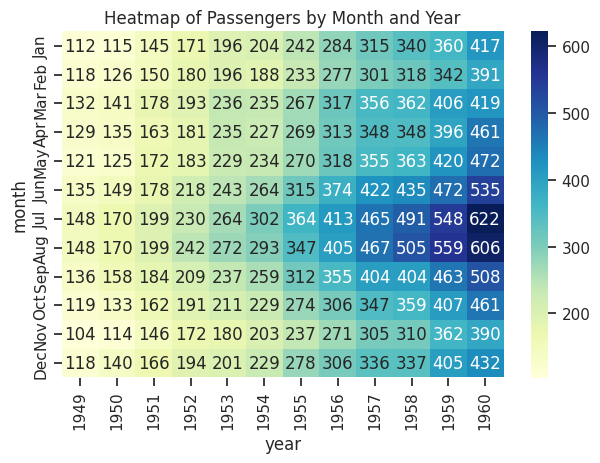

In [13]:
flights_pivot_df = flights_df.pivot(index='month', columns='year', values='passengers')
sns.heatmap(flights_pivot_df, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Heatmap of Passengers by Month and Year')
plt.tight_layout()

---
## 6. Best Practice — Seaborn inside the Matplotlib OO API

**Definition.** The recommended way to write Seaborn for anything real: create the figure and axes
yourself with `plt.subplots()`, tell the Seaborn function which Axes to draw on via `ax=`, then use
Matplotlib's methods for titles, labels and layout. Seaborn does the statistics; Matplotlib owns the
figure.

**Usage**

```python
fig, ax = plt.subplots()
sns.lineplot(data=df, x='...', y='...', hue='...', ax=ax)
ax.set_title('...')
ax.set_xlabel('...')
fig.tight_layout()
```

**Actions in the cell below**
- `fig, ax = plt.subplots()` — the explicit figure and axes from section 10 of the Matplotlib
  notebook.
- `ax=ax` — **the key argument.** It tells `lineplot` to draw onto that Axes instead of grabbing
  whatever is "current". Only **axes-level** functions accept it — `relplot` would raise a
  `TypeError` here.
- `marker='o'` — an unrecognised keyword like this is **passed straight through to
  `matplotlib.plot()`**. That pass-through is how any Matplotlib styling argument reaches the
  underlying artist.
- `errorbar=None` — switch off the confidence band from 2.5. Sensible here: `x='day'` is a category
  with many bills per day, so the default band would be wide and distracting.
- `ax.set_title()` / `.set_xlabel()` / `.set_ylabel()` — Matplotlib methods, overriding the column
  names Seaborn used by default. **Units belong here** — `'Total Bill ($)'` says something the bare
  column name `total_bill` does not.
- `fig.tight_layout()` — layout on the figure, as always.

**Why this is the recommended pattern**

| | |
| --- | --- |
| Composable | the chart can go into any panel of a `plt.subplots()` grid |
| Controllable | every Matplotlib method is available on `ax` and `fig` |
| Saveable | `fig.savefig('out.png', dpi=300, bbox_inches='tight')` |
| Explicit | no dependence on which figure happens to be current |

**A line chart over days is a slight stretch** — `day` is categorical, so the connecting segments
imply a continuity between Thursday and Friday that isn't really there (the same caveat as section
2.3 of the Matplotlib notebook). `sns.pointplot()` is the honest version of this chart: same means
and markers, no misleading interpolation.


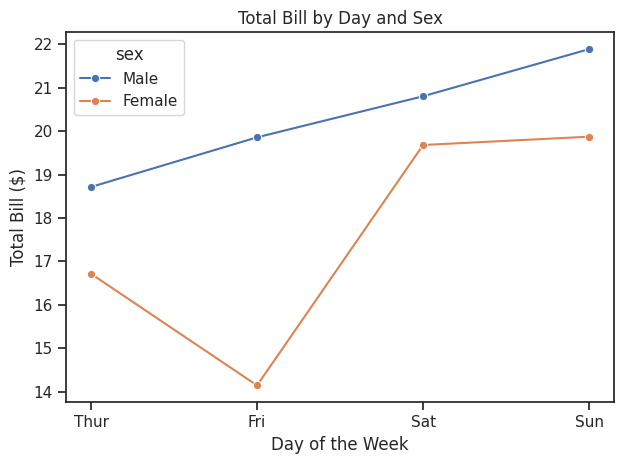

In [14]:
#recomded best practce
fig,ax = plt.subplots()
sns.lineplot(data=tips_df, x='day', y='total_bill',hue='sex',ax=ax,marker='o',errorbar=None)
ax.set_title('Total Bill by Day and Sex')
ax.set_xlabel('Day of the Week')
ax.set_ylabel('Total Bill ($)')

fig.tight_layout()

---
# Summary / Cheat Sheet

## Setup

| Task | Call |
| --- | --- |
| Import | `import seaborn as sns` · `import matplotlib.pyplot as plt` |
| Apply Seaborn defaults | `sns.set_theme(style='whitegrid', context='notebook')` |
| List example datasets | `sns.get_dataset_names()` (needs internet) |
| Load one | `df = sns.load_dataset('tips')` |

## The plot families

| Family | Figure-level | Axes-level | Shows |
| --- | --- | --- | --- |
| Relational | `relplot` | `scatterplot` · `lineplot` | how two numeric variables relate |
| Categorical | `catplot` | `barplot` · `boxplot` · `violinplot` · `countplot` · `pointplot` | a number across categories |
| Distribution | `displot` | `histplot` · `kdeplot` · `ecdfplot` | how one variable is spread |
| Matrix | — | `heatmap` · `clustermap` | a value across two categorical axes |
| Regression | `lmplot` | `regplot` | a fitted trend line |

## Semantic mappings — the core idea

| Argument | Maps a column to |
| --- | --- |
| `x`, `y` | position |
| `hue` | colour |
| `size` | marker size / line width |
| `style` | marker shape / dash pattern |
| `col`, `row` | separate panels — **figure-level only** |
| `order`, `hue_order` | the order categories appear in |

## Statistical defaults worth knowing

| Function | Silently does | Turn off with |
| --- | --- | --- |
| `lineplot` | means repeated y values, shades a 95% CI | `errorbar=None` |
| `barplot` | plots the **mean**, with a 95% CI error bar | `estimator='median'`, `errorbar=None` |
| `histplot` | chooses `bins='auto'` | `bins=20` |
| all | drops rows with missing values | — (check `df.isna().sum()`) |

## Figure-level vs axes-level

| | Axes-level | Figure-level |
| --- | --- | --- |
| Returns | `matplotlib.axes.Axes` | `seaborn.FacetGrid` |
| Accepts `ax=` | ✅ | ❌ |
| Facets with `col=` / `row=` | ❌ | ✅ |
| Fits in `plt.subplots()` | ✅ | ❌ |
| Select the chart type | the function name | `kind=` |

**Use axes-level + `ax=` for anything you intend to lay out or save; figure-level for quick
exploration and faceting.**

## Reshaping for a heatmap

```python
wide = long_df.pivot(index='rows', columns='cols', values='cells')
sns.heatmap(wide, annot=True, fmt='d', cmap='YlGnBu')
```

## Seaborn ↔ Matplotlib

Seaborn has **no** `show`, `savefig`, `subplots`, `title` or `xlabel` of its own — all of that stays
in Matplotlib:

| Task | Call |
| --- | --- |
| Title and labels | `ax.set_title()` · `ax.set_xlabel()` · `ax.set_ylabel()` |
| Layout | `fig.tight_layout()` |
| Save | `fig.savefig('out.png', dpi=300, bbox_inches='tight')` |
| Show | `plt.show()` |
| Same, on a figure-level plot | `g.figure` (the `FacetGrid`'s figure), or `g.set_axis_labels(...)` |

## Gotchas worth memorising

1. **Tidy data in.** One row per observation, one column per variable — then plot by column name.
2. `sns.set_theme()` is **global** and restyles Matplotlib charts too; importing seaborn alone does
   not apply it.
3. **Figure-level functions reject `ax=`.** If you need `ax=`, you want `scatterplot`, not `relplot`.
4. `lineplot` and `barplot` **aggregate silently** — a line through repeated x values is a mean, not
   your raw data.
5. `annot=True` on a heatmap needs `fmt=` matching the dtype (`'d'` for integers), or values render
   in scientific notation.
6. `heatmap` wants **wide** data; everything else wants **long**. `pivot()` converts.
7. Rows with `NaN` are dropped without a warning — the plotted count can be smaller than the
   DataFrame.
8. Category order follows the data, not the values. Use `order=` to control it.
9. Unrecognised keyword arguments are **passed through to Matplotlib** — that's a feature, and how
   `marker='o'` reaches the line.
10. Seaborn's job is statistics and defaults; **the figure is still Matplotlib's**.

## Where to go next

- `sns.pairplot(df, hue='species')` — every numeric column against every other, in one grid.
- `sns.jointplot(...)` — a scatter with marginal distributions on both axes.
- `sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', center=0)` — the
  correlation-matrix idiom.
- `sns.FacetGrid` / `sns.catplot(col=...)` — faceting in depth.
- `sns.set_palette()` and `sns.color_palette()` — colour, including colour-blind-safe options.
